**Tidy Data Project**

The first section of this project will outline tidying the dataset for visualizations. The dataset is called "2008 Olympic Medalists" and is gathered from this source: https://edjnet.github.io/OlympicsGoNUTS/2008/

After setting up the project by importing the libraries and the dataset, the first step of the tidy data process will be using the pd.melt() function to ensure columns become rows for easy data manipulation. Medalist_name are labeled as id_vars since they do not change. Gender_sport is the new collumn being created to store previous column names, so it is labeled as var_name. value_name is 'medal' since it will also be a new column but contains the new values of the medal type (bronze, silver, etc).

After that, I wanted to ensure no "NaN" values would appear, so I used the dropna() function. 

From there, I noticed 'gender_sport' was still a column which violates tidy data principles. Gender and sport should have their own respective columns, so I used the str.split() function to execute that issue. The 
df.drop() function below that is a subset of this same goal. 

The str.split function in the next line ensures sports are separated.

Finally, I used the df.to_csv() function to make a new csv file, that way I could view my progress on tidying the dataset. This csv file is accessible in the TidyData_Project folder.

For all steps and specific functions used in the tidy data process, refer to the pandas cheat sheet. 

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Tidying ---------------------------------------------------------------------------
df = pd.read_csv('medalists.csv')

df_melted = pd.melt(df, id_vars = ['medalist_name'],
                    var_name = 'gender_sport',
                    value_name = 'medal')

df_tidy = df_melted.dropna(subset=["medal"]).copy()

df_tidy[['gender', 'sport']] = df_tidy['gender_sport'].str.split('_', expand=True)
df_tidy.drop(columns=["gender_sport"], inplace=True)

df_tidy['sport'] = df_tidy['sport'].str.replace(' and ', ' & ')

df_tidy.to_csv('tidy_medalists.csv', index=False)

**Visualizations**

Below, there are two visualizations to help better understand the information contained by the dataset, and to show the data is now tidy. 

Visualizaiton 1, Pie Chart

The first visualization type is a pie chart that will show medals by the type of medal (bronze, silver, and gold)

To execute the pie chart, we first have to convert the medals into a numerical variable since "bronze", "silver", and "gold" medals are categorical variables. I used the value_counts() (refer to the pandas cheat sheet) function to instead count the number of medals that exist in the dataset.

From there, I filled in count as the y value, which for pie charts indicates how big the slice will be. The labels are what we created df_medal for: assigns each type and number of medals to each slice. autopct just calculates and displays the correct percentage in the figure. Finally, plt.ylabel('') ensures that the 'count' text does not appear as text on the figure. 

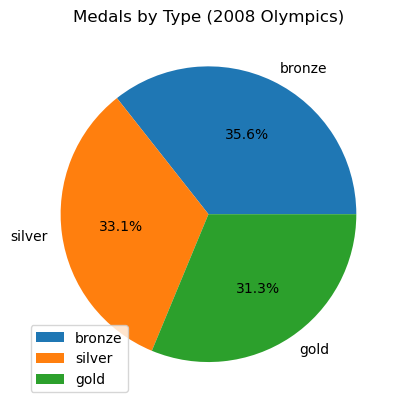

In [3]:
df_medal = df_tidy['medal'].value_counts().reset_index()

df_medal.plot.pie(y = 'count', labels = df_medal['medal'], autopct='%1.1f%%', title='Medals by Type (2008 Olympics)')
plt.ylabel('')
plt.show()

Visualization 2, Bar Chart

The second visualization type is a bar chart that will show medals by the type of sport.

To execute the bar chart, we again have to convert type of sport into a numerical variable since they are categorical variables. I used the same value_counts() function.

From there, I labeled the x and y axes by sport and count. After coloring the bars and labeling the chart, I added visual labels to the x and y axes by using the plt.xlabel and plt.ylabel. The plt.xticks function was added after my initial code was run since the labels for each of the sports on the x-axis overlapped with each other, so the rotation=45 puts each sport name at a 45 degree angle, and ha='right' alligns them horizontally under each tick. Finally, the plt.tight_layout() ensures nothing is cutoff. 

For all functions used in the bar chart, refer to the pandas cheat sheet for specific details and instructions.


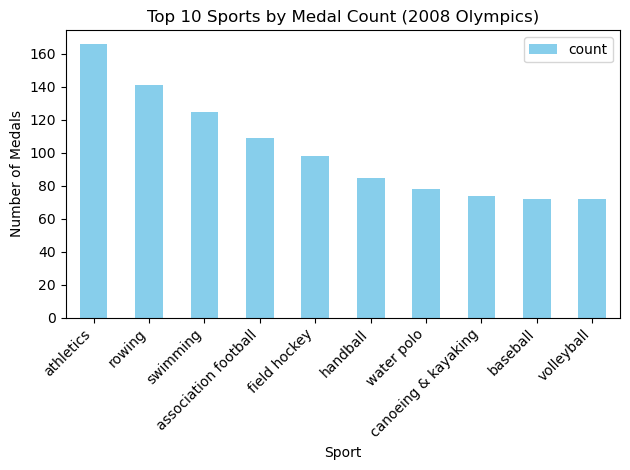

In [4]:
df_sport = df_tidy['sport'].value_counts().reset_index().head(10)

df_sport.plot.bar(x = 'sport', y = 'count', color='skyblue')
plt.title('Top 10 Sports by Medal Count (2008 Olympics)')
plt.xlabel('Sport')
plt.ylabel('Number of Medals')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Pivot Table**

To conclude this project, I added a pivot table to get a simple count on how many medals were awarded to each gender for their respective sports. I used the df.pivot_table function from the pandas cheat sheet to execute this. 

Within the function, first I specified 'medal' as the column whose data is being added. Index=sport places each sport as a column in the table, which are split above with the main gender columns. aggfunc specifies to vscode to count each medal so that they are added. Lastly, fill_value gets rid of any "NaN" or 0 values. 

In [5]:
df_pivot = df_tidy.pivot_table(values = 'medal', index = ['sport'], columns = ['gender'], aggfunc = 'count', fill_value = 0)
print(df_pivot)

gender                 female  male
sport                              
archery                     9    11
artistic gymnastics        20    29
association football       54    55
athletics                  81    85
badminton                  10    12
baseball                    0    72
basketball                 36    35
beach volleyball            6     6
bmx                         3     3
boxing                      0    44
canoeing & kayaking        21    53
diving                     13    16
equestrian sport           20    18
fencing                    26    28
field hockey               48    50
freestyle wrestling        16    28
greco-roman wrestling       0    27
handball                   42    43
judo                       28    28
modern pentathlon           2     3
mountain biking             3     3
rhythmic gymnastics        21     0
road bicycle racing         6     5
rowing                     58    83
sailing                    21    33
shooting sport             1